In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold, validation_curve, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, make_scorer
import warnings

warnings.filterwarnings('ignore')

Reading and splitting data

In [2]:
df = pd.read_csv('ddos_dataset_pre_PCA.csv', dtype={'SimillarHTTP':str}, index_col=0)

to_drop = ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']

df = df.drop(columns=to_drop)
df.columns

#Separate features and labels
X = df.drop(columns=['label'])
y = df['label']

#Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    train_size=0.7,
    random_state=18
)

#Standardize data
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled, X_test_scaled = scaler.transform(X_train), scaler.transform(X_test)

# Random Forest
Training the model with random splitted data

--- Base Random Forest Report TRAIN ---
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      3961
    ddos_dns       1.00      1.00      1.00      3758
   ddos_ldap       1.00      1.00      1.00      4149
  ddos_mssql       1.00      1.00      1.00      4138
ddos_netbios       1.00      1.00      1.00      4081
    ddos_ntp       1.00      1.00      1.00       690
   ddos_snmp       1.00      1.00      1.00      4189
   ddos_ssdp       1.00      1.00      1.00      4179
    ddos_syn       1.00      1.00      1.00      3836
   ddos_tftp       1.00      1.00      1.00      3683
    ddos_udp       1.00      1.00      1.00      4113
ddos_udp_lag       1.00      1.00      1.00      4190

    accuracy                           1.00     44967
   macro avg       1.00      1.00      1.00     44967
weighted avg       1.00      1.00      1.00     44967



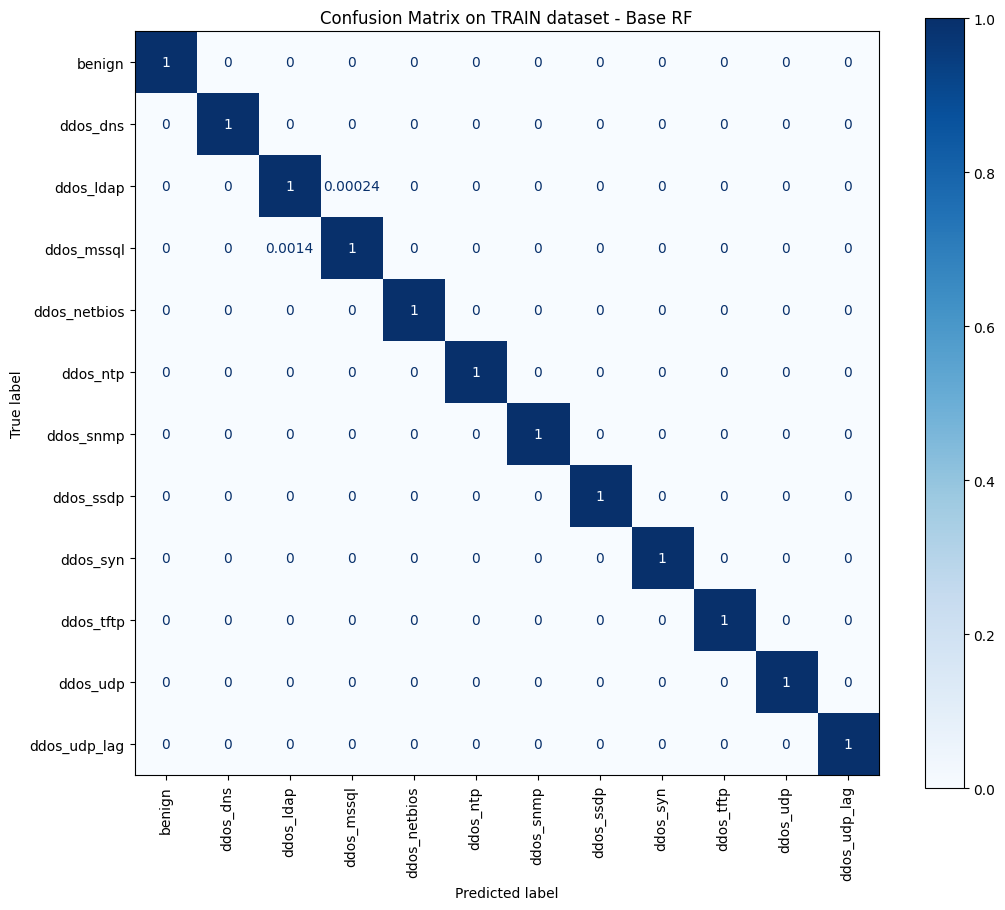

In [3]:
# Training Base Model
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)

# Prediction
y_pred_base_train = rf_base.predict(X_train)

# Report
print("--- Base Random Forest Report TRAIN ---")
print(classification_report(y_train, y_pred_base_train))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_base_train,
    cmap='Blues',
    xticks_rotation='vertical',
    normalize='true',
    ax=ax
)
plt.title("Confusion Matrix on TRAIN dataset - Base RF")
plt.grid(False)
plt.show()

--- Base Random Forest Report ---
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      1697
    ddos_dns       0.99      0.99      0.99      1611
   ddos_ldap       0.84      0.82      0.83      1779
  ddos_mssql       0.82      0.84      0.83      1773
ddos_netbios       1.00      1.00      1.00      1749
    ddos_ntp       0.98      0.99      0.98       296
   ddos_snmp       1.00      1.00      1.00      1795
   ddos_ssdp       1.00      1.00      1.00      1791
    ddos_syn       0.98      0.99      0.98      1644
   ddos_tftp       0.98      0.98      0.98      1578
    ddos_udp       1.00      1.00      1.00      1763
ddos_udp_lag       1.00      1.00      1.00      1796

    accuracy                           0.96     19272
   macro avg       0.97      0.97      0.97     19272
weighted avg       0.96      0.96      0.96     19272



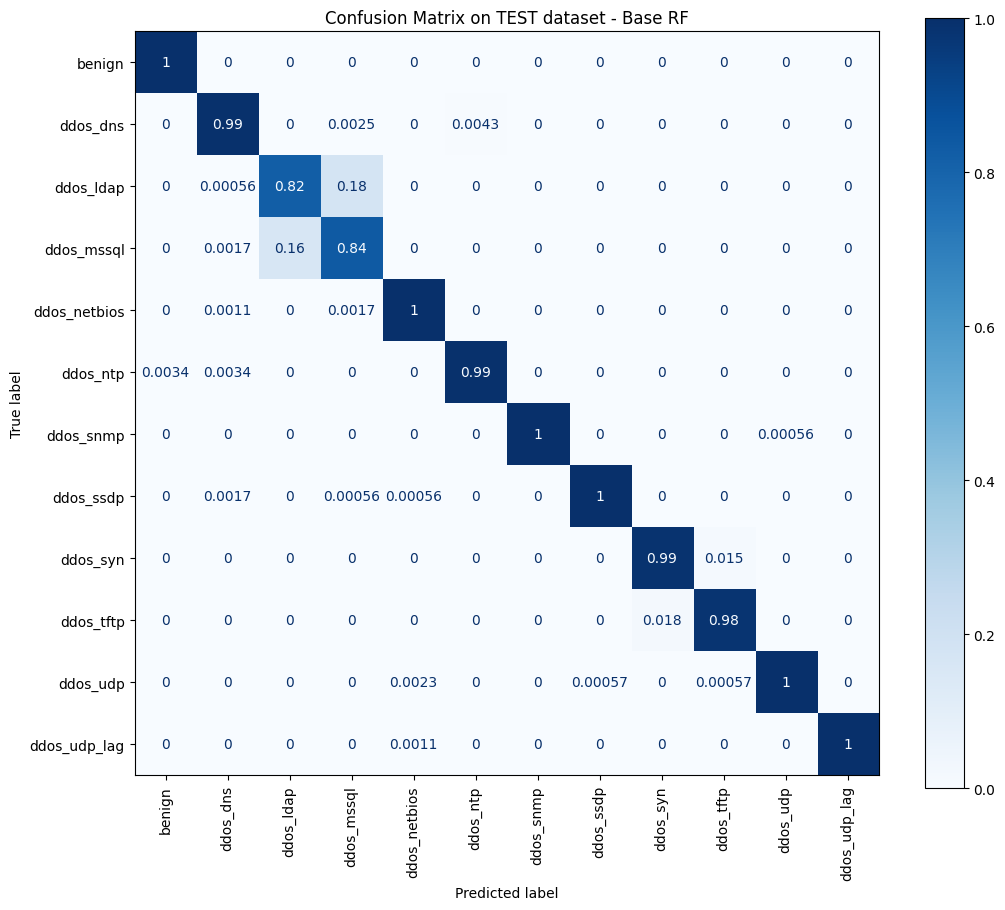

In [ ]:
# Training Base Model
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)

# Prediction
y_pred_base_test = rf_base.predict(X_test)

# Report
print("--- Base Random Forest Report TEST ---")
print(classification_report(y_test, y_pred_base_test))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_base_test,
    cmap='Blues',
    xticks_rotation='vertical',
    normalize='true',
    ax=ax
)
plt.title("Confusion Matrix on TEST dataset - Base RF")
plt.grid(False)
plt.show()

## Validation curve
Validation curve on some usefull parameters in order to find the best search interval for gridsearch

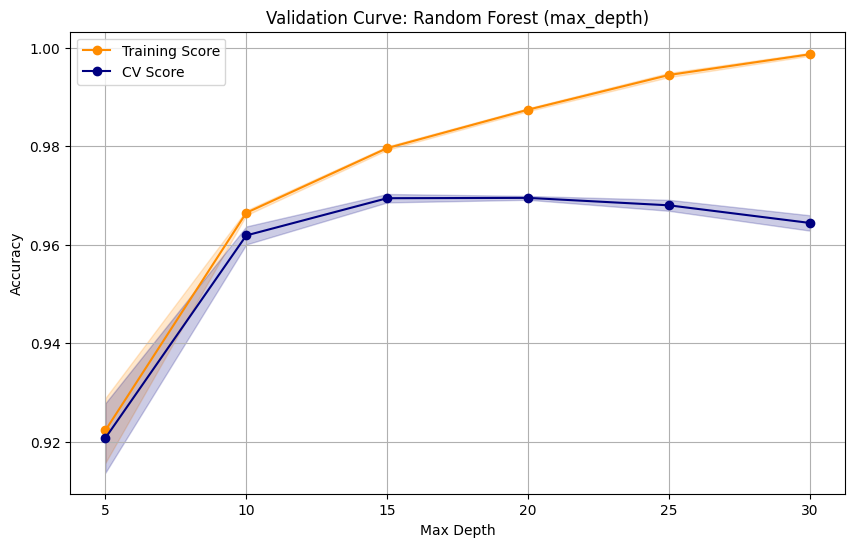

In [5]:
# --- Validation Curve (Max Depth) ---

# Definiamo il range da testare
param_range = [5, 10, 15, 20, 25, 30]

# Calcolo curve
train_scores, test_scores = validation_curve(
    estimator=RandomForestClassifier(random_state=42),
    X=X_train,
    y=y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=5, 
    scoring="accuracy",
    n_jobs=-1
)

# Medie e Deviazioni Standard
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(param_range, train_mean, label="Training Score", color="darkorange", marker='o')
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2, color="darkorange")
plt.plot(param_range, test_mean, label="CV Score", color="navy", marker='o')
plt.fill_between(param_range, test_mean - test_std, test_mean + test_std, alpha=0.2, color="navy")

plt.title("Validation Curve: Random Forest (max_depth)")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.grid(True)
plt.show()

## Grid Search

In [4]:
grid = {
    'n_estimators': [50, 100, 150],   # Numero alberi
    'max_depth': [10, 15, 20],        # Profondità (basata sulla curva sopra)
    'criterion': ['gini', 'entropy'], # Qualità dello split
    'min_samples_leaf': [1, 2, 4]     # Regolarizzazione
}

# Metriche
scoring_metrics = {
    'accuracy': make_scorer(accuracy_score),
    'f1': make_scorer(f1_score, average='weighted')
}

# Configurazione Grid Search
grid_search = GridSearchCV(
    estimator = RandomForestClassifier(random_state=42), 
    param_grid = grid, 
    n_jobs = -1, 
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42), 
    scoring = scoring_metrics,
    refit = 'accuracy', 
    error_score = 0,
    verbose = 1
)

print("Starting Grid Search...")
grid_search_result = grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search_result.best_params_}")
print(f"Best Accuracy: {grid_search_result.best_score_:.4f}")

best_rf_model = grid_search_result.best_estimator_

Starting Grid Search...
Fitting 15 folds for each of 54 candidates, totalling 810 fits
Best Parameters: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 100}
Best Accuracy: 0.9704


--- Best Random Forest Report ---
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      1697
    ddos_dns       1.00      0.99      0.99      1611
   ddos_ldap       0.83      0.92      0.87      1779
  ddos_mssql       0.91      0.81      0.86      1773
ddos_netbios       1.00      1.00      1.00      1749
    ddos_ntp       0.98      0.98      0.98       296
   ddos_snmp       1.00      1.00      1.00      1795
   ddos_ssdp       1.00      1.00      1.00      1791
    ddos_syn       0.98      0.99      0.98      1644
   ddos_tftp       0.98      0.98      0.98      1578
    ddos_udp       1.00      1.00      1.00      1763
ddos_udp_lag       1.00      1.00      1.00      1796

    accuracy                           0.97     19272
   macro avg       0.97      0.97      0.97     19272
weighted avg       0.97      0.97      0.97     19272



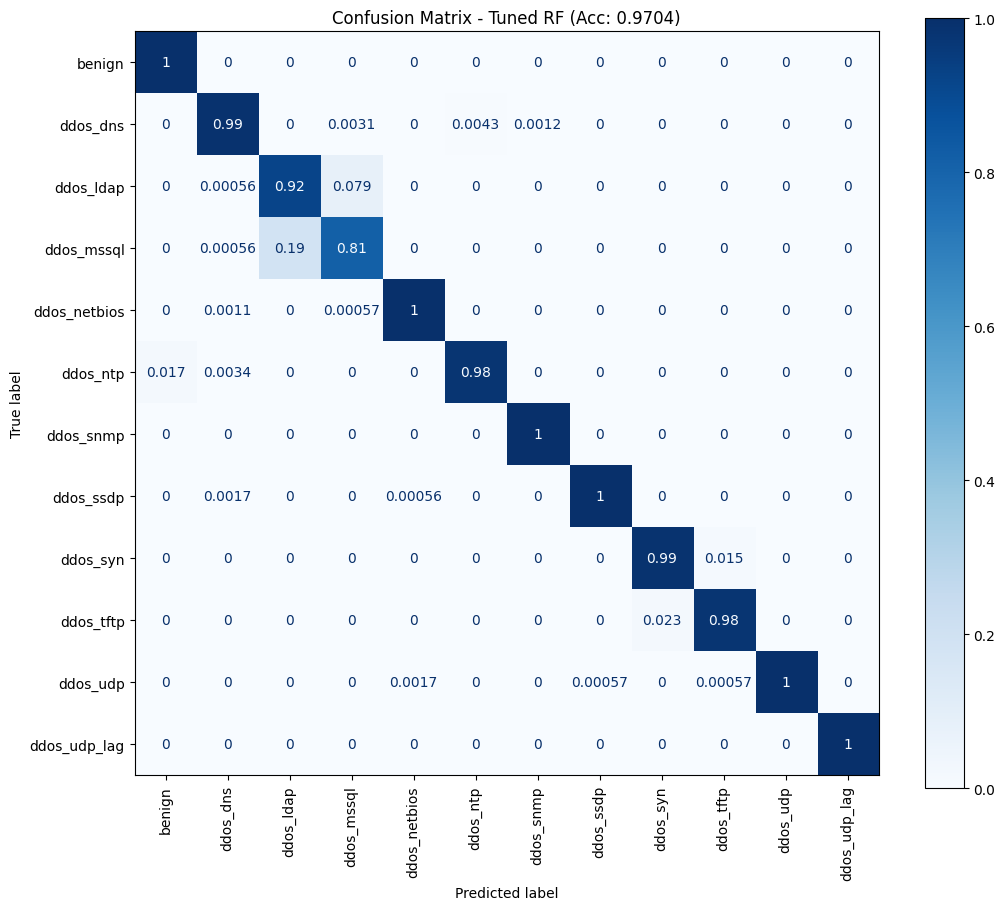

In [11]:
# --- Final Model Evaluation ---

# Predizioni sul Test Set col modello migliore
y_pred_best = best_rf_model.predict(X_test)

# Report Testuale
print("--- Best Random Forest Report ---")
print(classification_report(y_test, y_pred_best))

# Confusion Matrix Finale
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    cmap='Blues',
    xticks_rotation='vertical',
    normalize='true',
    ax=ax
)
plt.title(f"Confusion Matrix - Tuned RF (Acc: {grid_search_result.best_score_:.4f})")
plt.grid(False)
plt.show()

### Learning curve

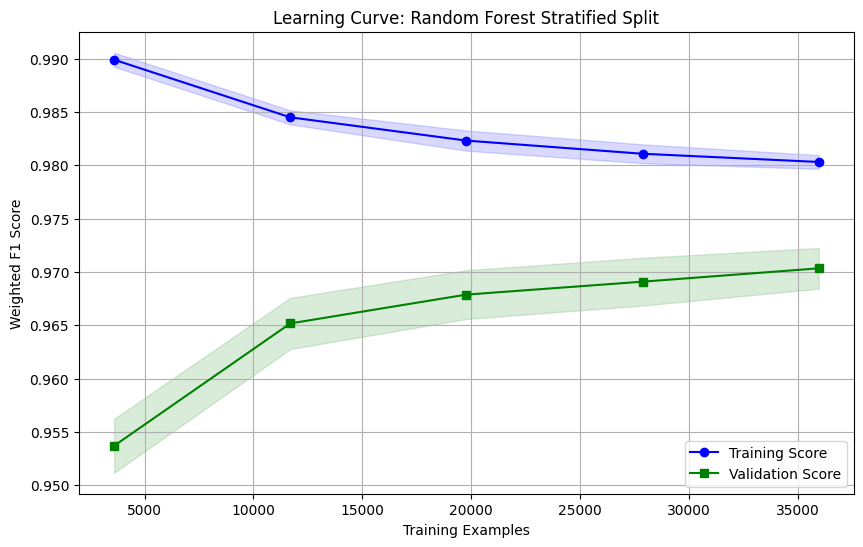

In [5]:
train_sizes = np.linspace(0.1, 1.0, 5) # Step dal 10% al 100%


train_sizes_abs, train_scores, test_scores = learning_curve(
    estimator=best_rf_model,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted', 
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot
plt.figure(figsize=(10, 6))

# Training Score
plt.plot(train_sizes_abs, train_mean, color='blue', marker='o', label='Training Score')
plt.fill_between(train_sizes_abs, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

# Validation Score
plt.plot(train_sizes_abs, test_mean, color='green', marker='s', label='Validation Score')
plt.fill_between(train_sizes_abs, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

plt.title('Learning Curve: Random Forest Stratified Split')
plt.xlabel('Training Examples')
plt.ylabel('Weighted F1 Score')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

--- Training Set Classification Report ---
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      3961
    ddos_dns       1.00      1.00      1.00      3758
   ddos_ldap       0.86      0.96      0.91      4149
  ddos_mssql       0.95      0.85      0.90      4138
ddos_netbios       1.00      1.00      1.00      4081
    ddos_ntp       1.00      1.00      1.00       690
   ddos_snmp       1.00      1.00      1.00      4189
   ddos_ssdp       1.00      1.00      1.00      4179
    ddos_syn       0.98      0.99      0.98      3836
   ddos_tftp       0.99      0.98      0.98      3683
    ddos_udp       1.00      1.00      1.00      4113
ddos_udp_lag       1.00      1.00      1.00      4190

    accuracy                           0.98     44967
   macro avg       0.98      0.98      0.98     44967
weighted avg       0.98      0.98      0.98     44967


--- Test Set Classification Report ---
              precision    recall  f1-score   supp

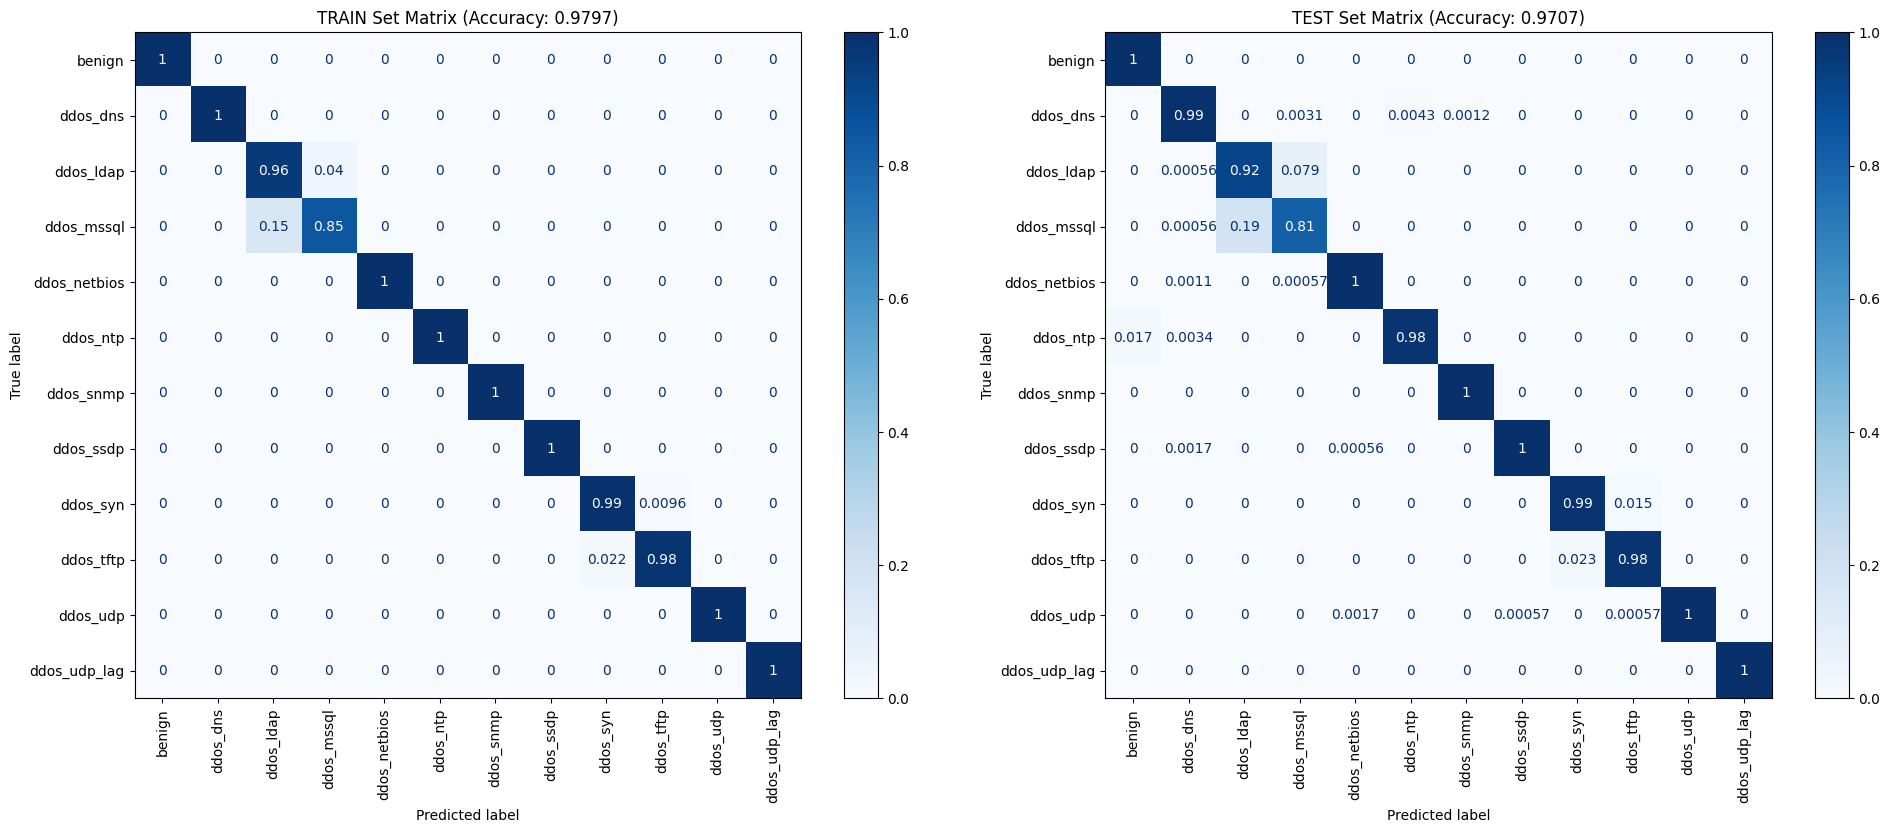

In [6]:
# --- Train vs Test Comparison ---

# Generazione predizioni
y_train_pred = best_rf_model.predict(X_train)
y_test_pred = best_rf_model.predict(X_test)

# Report Testuali
print("--- Training Set Classification Report ---")
print(classification_report(y_train, y_train_pred))
print("\n--- Test Set Classification Report ---")
print(classification_report(y_test, y_test_pred))

# Plot Matrici Affiancate
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Train Matrix (Sinistra)
ConfusionMatrixDisplay.from_predictions(
    y_train, y_train_pred,
    cmap='Blues',
    xticks_rotation='vertical',
    normalize='true',
    ax=axes[0]
)
axes[0].set_title(f'TRAIN Set Matrix (Accuracy: {accuracy_score(y_train, y_train_pred):.4f})')
axes[0].grid(False)

# Test Matrix (Destra)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    cmap='Blues',
    xticks_rotation='vertical',
    normalize='true',
    ax=axes[1]
)
axes[1].set_title(f'TEST Set Matrix (Accuracy: {accuracy_score(y_test, y_test_pred):.4f})')
axes[1].grid(False)

plt.tight_layout()
plt.show()

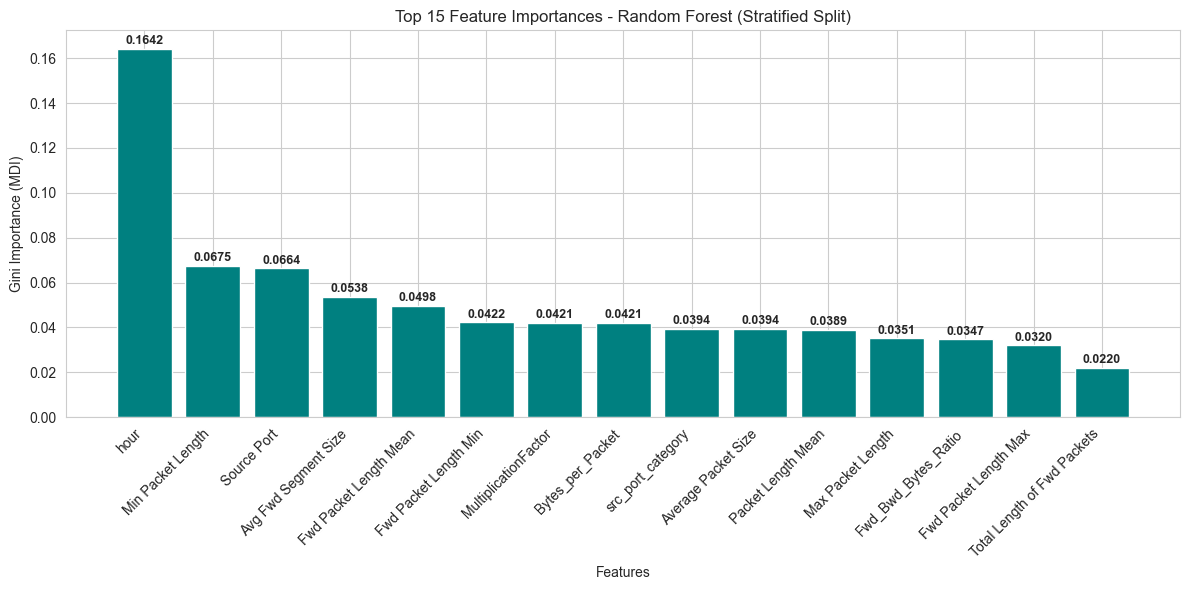

In [7]:
# --- Feature Importance ---

# Estrazione importanze
importances_rs = best_rf_model.feature_importances_
indices_rs = np.argsort(importances_rs)[::-1] # Ordine decrescente
feature_names_rs = X.columns

plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

plt.bar(range(15), importances_rs[indices_rs[:15]], align="center", color="teal")
plt.xticks(range(15), feature_names_rs[indices_rs[:15]], rotation=45, ha='right')

# Add numerical labels
for i, val in enumerate(importances_rs[indices_rs[:15]]):
    plt.text(i, val + 0.002, f'{val:.4f}', ha='center', fontsize=9, fontweight='bold')

plt.title("Top 15 Feature Importances - Random Forest (Stratified Split)")
plt.ylabel("Gini Importance (MDI)")
plt.xlabel("Features")
plt.tight_layout()
plt.show()